# Phân tích nghỉ việc nhân sự — IBM HR Analytics Employee Attrition & Performance
**Mid-term 2 – Project 5 | Khoa học dữ liệu cơ bản trong kinh tế và kinh doanh (NEU)**

Nhóm: *[Họ tên – MSSV thành viên 1]*, *[thành viên 2]*, *[thành viên 3]*
GitHub: *[dán link repo public]*

**Câu hỏi kinh doanh:** Nhân viên nào có nguy cơ nghỉ việc, vì sao, và doanh nghiệp nên can thiệp ở đâu để giảm chi phí nghỉ việc?

Notebook đi theo 4 giai đoạn của đề bài:
1. Thu thập và đánh giá dữ liệu ban đầu
2. Tiền xử lý và làm sạch dữ liệu
3. Phân tích, kiểm định giả thuyết, trực quan hóa (+ mô hình dự báo rủi ro)
4. Đánh giá tác động và khuyến nghị

> Chạy được bằng **Runtime → Run all** trên Google Colab. Dữ liệu tự tải từ kho GitHub chính thức của IBM nếu không có file cục bộ.

In [1]:
# ============================================================
# 0. THIẾT LẬP MÔI TRƯỜNG: thư viện, bảng màu, hàm tiện ích
# ============================================================
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix,
                             classification_report, recall_score, precision_score, f1_score)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Bảng màu đã kiểm tra an toàn cho người mù màu: xanh = Ở lại, cam = Nghỉ việc
C_STAY, C_LEAVE, C_GREY, C_INK = "#2a78d6", "#eb6834", "#b8b6ae", "#52514e"
CMAP_RATE = LinearSegmentedColormap.from_list("rate", ["#fcfcfb", "#f6c7ad", "#eb6834", "#a8401a"])
CMAP_DIV  = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#f3a17c", "#b4451a"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": C_INK, "axes.labelcolor": C_INK, "xtick.color": C_INK, "ytick.color": C_INK,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    # Lưu hình vào thư mục figures/ để dùng trong báo cáo PDF
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

def attr_rate(frame, col):
    # Tỷ lệ nghỉ việc + cỡ mẫu theo từng nhóm của biến col
    g = frame.groupby(col, observed=True)["AttritionFlag"].agg(["mean", "size"])
    g.columns = ["rate", "n"]
    return g

def wilson_ci(k, n, z=1.96):
    # Khoảng tin cậy Wilson 95% cho tỷ lệ (ổn định hơn xấp xỉ chuẩn khi n nhỏ)
    p = k / n
    den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - half, centre + half

def cramers_v(table):
    # Cramér's V: độ lớn hiệu ứng cho kiểm định Chi-bình phương (0 = không liên hệ, 1 = hoàn toàn)
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))
print("Môi trường sẵn sàng.")

Môi trường sẵn sàng.


# GIAI ĐOẠN 1 — Thu thập và đánh giá dữ liệu ban đầu
## 1.1 Nguồn dữ liệu
Bộ dữ liệu **IBM HR Analytics Employee Attrition & Performance** (Kaggle, tác giả pavansubhasht) do các nhà khoa học dữ liệu IBM tạo ra (*fictional data*) để mô phỏng hồ sơ nhân sự. Gồm **1 file CSV** `WA_Fn-UseC_-HR-Employee-Attrition.csv`, không cần ghép bảng.

**Mục tiêu bài toán:** biến mục tiêu `Attrition` (Yes/No) → bài toán *phân loại nhị phân* và *phân tích nguyên nhân*.

In [2]:
# 1.1 Tải dữ liệu: ưu tiên file cục bộ (repo GitHub của nhóm), nếu không có thì tải từ kho chính thức của IBM
LOCAL = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
URL = "https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv"
src = LOCAL if os.path.exists(LOCAL) else URL

# encoding='utf-8-sig': an toàn nếu file có ký tự BOM ở đầu (thường gặp khi xuất CSV từ Excel)
raw = pd.read_csv(src, encoding="utf-8-sig")
print("Nguồn:", src)
print("Kích thước:", raw.shape, "→", raw.shape[0], "quan sát,", raw.shape[1], "thuộc tính")
raw.head()

Nguồn: WA_Fn-UseC_-HR-Employee-Attrition.csv
Kích thước: (1470, 35) → 1470 quan sát, 35 thuộc tính


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


## 1.2 Từ điển dữ liệu
Nhiều cột số thực chất là **thang đo thứ bậc (ordinal)** đã được mã hóa; cần hiểu đúng trước khi xử lý.

In [3]:
# 1.2 Từ điển dữ liệu: phân nhóm thuộc tính theo bản chất (không chỉ theo kiểu dữ liệu máy đọc)
dictionary = pd.DataFrame([
    ("Biến mục tiêu", "Attrition", "Yes/No – nhân viên đã nghỉ việc"),
    ("Nhân khẩu học", "Age, Gender, MaritalStatus, DistanceFromHome", "Tuổi, giới tính, hôn nhân, khoảng cách nhà"),
    ("Học vấn", "Education (1-5), EducationField", "1=Below College … 5=Doctor"),
    ("Công việc", "Department, JobRole, JobLevel (1-5), BusinessTravel, OverTime", "Vị trí, cấp bậc, công tác, làm thêm giờ"),
    ("Thu nhập", "MonthlyIncome, PercentSalaryHike, StockOptionLevel (0-3)", "Lương tháng, % tăng lương, mức cổ phiếu"),
    ("Thu nhập (nghi vấn)", "DailyRate, HourlyRate, MonthlyRate", "Ý nghĩa không được mô tả – sẽ kiểm tra"),
    ("Khảo sát (1-4)", "EnvironmentSatisfaction, JobSatisfaction, RelationshipSatisfaction, JobInvolvement, WorkLifeBalance", "1=Low/Bad … 4=Very High/Best"),
    ("Hiệu suất", "PerformanceRating (1-4), TrainingTimesLastYear", "1=Low … 4=Outstanding"),
    ("Thâm niên", "TotalWorkingYears, NumCompaniesWorked, YearsAtCompany, YearsInCurrentRole, YearsSinceLastPromotion, YearsWithCurrManager", "Đơn vị: năm"),
    ("Kỹ thuật", "EmployeeNumber, EmployeeCount, Over18, StandardHours", "Mã định danh và cột hằng"),
], columns=["Nhóm", "Thuộc tính", "Ghi chú"])
dictionary

,Nhóm,Thuộc tính,Ghi chú
0,Biến mục tiêu,Attrition,Yes/No – nhân viên đã nghỉ việc
1,Nhân khẩu học,"Age, Gender, MaritalStatus, DistanceFromHome","Tuổi, giới tính, hôn nhân, khoảng cách nhà"
2,Học vấn,"Education (1-5), EducationField",1=Below College … 5=Doctor
3,Công việc,"Department, JobRole, JobLevel (1-5), BusinessT...","Vị trí, cấp bậc, công tác, làm thêm giờ"
4,Thu nhập,"MonthlyIncome, PercentSalaryHike, StockOptionL...","Lương tháng, % tăng lương, mức cổ phiếu"
5,Thu nhập (nghi vấn),"DailyRate, HourlyRate, MonthlyRate",Ý nghĩa không được mô tả – sẽ kiểm tra
6,Khảo sát (1-4),"EnvironmentSatisfaction, JobSatisfaction, Rela...",1=Low/Bad … 4=Very High/Best
7,Hiệu suất,"PerformanceRating (1-4), TrainingTimesLastYear",1=Low … 4=Outstanding
8,Thâm niên,"TotalWorkingYears, NumCompaniesWorked, YearsAt...",Đơn vị: năm
9,Kỹ thuật,"EmployeeNumber, EmployeeCount, Over18, Standar...",Mã định danh và cột hằng


In [4]:
# 1.3 Rà soát hiện trạng: kiểu dữ liệu, số giá trị duy nhất, tỷ lệ thiếu cho từng trường
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
    "ví dụ": raw.iloc[0],
})
print("Tổng số ô thiếu:", int(raw.isna().sum().sum()))
print("Số cột số:", raw.select_dtypes("number").shape[1], "| Số cột chữ:", raw.select_dtypes(exclude="number").shape[1])
profile.sort_values("n_unique")

Tổng số ô thiếu: 0
Số cột số: 26 | Số cột chữ: 9


,dtype,n_unique,missing,missing_%,ví dụ
EmployeeCount,int64,1,0,0.0,1
Over18,str,1,0,0.0,Y
StandardHours,int64,1,0,0.0,80
Attrition,str,2,0,0.0,Yes
OverTime,str,2,0,0.0,Yes
PerformanceRating,int64,2,0,0.0,3
Gender,str,2,0,0.0,Female
BusinessTravel,str,3,0,0.0,Travel_Rarely
Department,str,3,0,0.0,Sales
MaritalStatus,str,3,0,0.0,Single


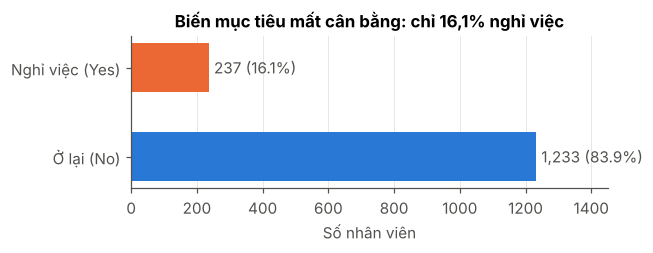

Tỷ lệ mất cân bằng ≈ 5.2 : 1


In [5]:
# 1.4 Phân phối biến mục tiêu: kiểm tra mất cân bằng lớp
counts = raw["Attrition"].value_counts()
share = raw["Attrition"].value_counts(normalize=True)
fig, ax = plt.subplots(figsize=(6, 2.4))
ax.barh(["Ở lại (No)", "Nghỉ việc (Yes)"], [counts["No"], counts["Yes"]],
        color=[C_STAY, C_LEAVE], height=0.55)
for i, k in enumerate(["No", "Yes"]):
    ax.text(counts[k] + 15, i, f"{counts[k]:,} ({share[k]:.1%})", va="center", color=C_INK)
ax.set_xlim(0, 1450); ax.set_xlabel("Số nhân viên"); ax.grid(axis="y", visible=False)
ax.set_title("Biến mục tiêu mất cân bằng: chỉ 16,1% nghỉ việc")
save(fig, "fig01_target")
print(f"Tỷ lệ mất cân bằng ≈ {counts['No']/counts['Yes']:.1f} : 1")

**Nhận xét Giai đoạn 1.** 1.470 quan sát × 35 thuộc tính (26 số, 9 chữ), **không có giá trị thiếu**, file đơn nên không phát sinh vấn đề khóa ngoại. Tuy nhiên “sạch về hình thức” chưa có nghĩa là “sạch về nội dung”: (i) 3 cột chỉ có 1 giá trị; (ii) nhiều cột số thực chất là thang thứ bậc; (iii) có những cột chưa rõ ngữ nghĩa (DailyRate, HourlyRate, MonthlyRate); (iv) biến mục tiêu mất cân bằng ≈ 5,2:1 → **Accuracy là thước đo đánh lừa** (đoán “No” cho tất cả đã đạt 83,9%), nên ở phần mô hình sẽ dùng ROC-AUC, PR-AUC và Recall.